# Is Dublin getting rainier?

How have rainfall amounts, rainy days, and wet-day patterns changed in Dublin—and can daily weather data help predict rain tomorrow?


## 1. Load and clean


In [74]:
import pandas as pd

df = pd.read_csv("../data/raw/dly532.csv", skiprows=44)
df.head()

,date,ind,maxtp,ind.1,mintp,igmin,gmin,ind.2,rain,cbl,...,hg,sun,dos,g_rad,soil,pe,evap,smd_wd,smd_md,smd_pd
0,01-jan-1942,0,9.7,0,6.8,0,4.7,2,0.0,1020.3,...,,0.0,0,,,1.1,1.4,,,
1,02-jan-1942,0,9.9,0,7.9,0,6.7,0,0.1,1016.2,...,,0.0,0,,,0.7,0.9,,,
2,03-jan-1942,0,11.2,0,8.9,0,7.2,0,1.5,1006.8,...,,0.1,0,,,0.5,0.6,,,
3,04-jan-1942,0,9.2,0,2.7,0,3.4,0,3.5,1001.5,...,,0.6,0,,,0.6,0.7,,,
4,05-jan-1942,0,3.5,1,-0.8,0,0.0,0,0.6,1013.4,...,,3.4,0,,,0.6,0.7,,,


In [75]:
cols = ["rain", "maxtp", "mintp", "cbl", "wdsp", "hg", "ddhm", "sun"]

for c in cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df[cols].dtypes

rain     float64
maxtp    float64
mintp    float64
cbl      float64
wdsp     float64
hg       float64
ddhm     float64
sun      float64
dtype: object

In [76]:
df["date"] = pd.to_datetime(df["date"], format="%d-%b-%Y")
df["date"].dtype

dtype('<M8[ns]')

In [77]:
expected = pd.date_range(df["date"].min(), df["date"].max())
print("Expected days:", len(expected))
print("Actual days:  ", len(df))
print("Missing:      ", len(expected) - len(df))

Expected days: 30954
Actual days:   30954
Missing:       0


The cleaned record contains 30,954 consecutive daily observations. Blank measurements in the source data were converted to missing values.


## 2. Is it always raining?


In [78]:
df["rain_day"] = df["rain"] >= 0.2
df["wet_day"] = df["rain"] >= 1.0
df[["date", "rain", "rain_day", "wet_day"]].head(10)

,date,rain,rain_day,wet_day
0,1942-01-01,0.0,False,False
1,1942-01-02,0.1,False,False
2,1942-01-03,1.5,True,True
3,1942-01-04,3.5,True,True
4,1942-01-05,0.6,True,False
5,1942-01-06,0.0,False,False
6,1942-01-07,0.0,False,False
7,1942-01-08,0.0,False,False
8,1942-01-09,0.2,True,False
9,1942-01-10,0.0,False,False


In [79]:
df["rain_day"] = df["rain"] >= 0.2
df["wet_day"] = df["rain"] >= 1.0

print(f"Rain days (≥0.2 mm): {df['rain_day'].mean():.1%}")
print(f"Wet days (≥1 mm):    {df['wet_day'].mean():.1%}")
print(f"Completely dry:      {(df['rain'] == 0).mean():.1%}")

Rain days (≥0.2 mm): 52.1%
Wet days (≥1 mm):    36.0%
Completely dry:      42.4%


Rain was recorded on 52.1% of days, but only 36.0% were wet (at least 1 mm); about a third of rain days were just drizzle. Completely dry days made up 42.4% of the record.


In [84]:
df["year"] = df["date"].dt.year
yearly_total = df.groupby("year")["rain"].sum()

In [85]:
complete_years = yearly_total.loc[:2025]

average_rainfall = complete_years.mean()
wettest_year = complete_years.idxmax()
wettest_amount = complete_years.max()
driest_year = complete_years.idxmin()
driest_amount = complete_years.min()

print(f"Average yearly rainfall: {average_rainfall:.0f} mm")
print(f"Wettest year: {wettest_year} ({wettest_amount:.0f} mm)")
print(f"Driest year: {driest_year} ({driest_amount:.0f} mm)")
print(f"2023 rank: {complete_years.rank(ascending=False, method='min').loc[2023]:.0f}")

Average yearly rainfall: 757 mm
Wettest year: 2002 (1096 mm)
Driest year: 1989 (555 mm)
2023 rank: 5


Across complete years, average rainfall was 757 mm. 2002 was wettest (1,096 mm), 1989 driest (555 mm), and 2023 ranked fifth wettest in 84 years.


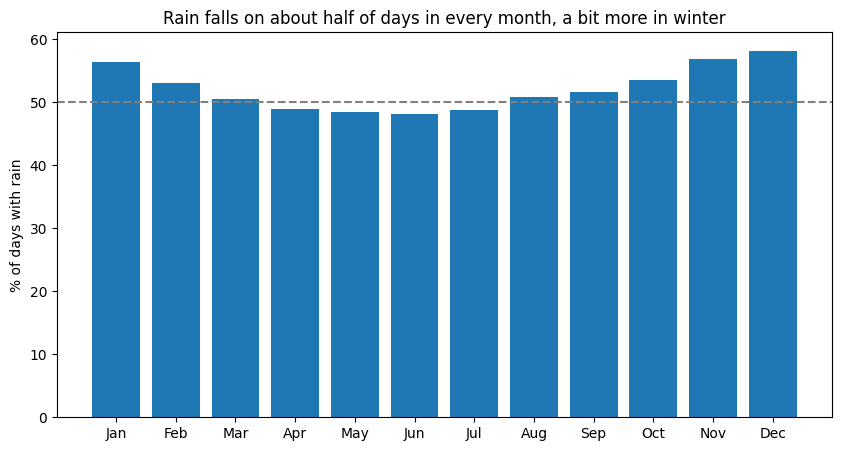

In [86]:
import matplotlib.pyplot as plt

df["month"] = df["date"].dt.month
by_month = df.groupby("month")["rain_day"].mean() * 100

months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(months, by_month)
ax.axhline(50, linestyle="--", color="grey")   # the "half of days" line
ax.set_ylabel("% of days with rain")
ax.set_title("Rain falls on about half of days in every month, a bit more in winter")
plt.savefig("../figures/01_rain_days_by_month.png", dpi=200, bbox_inches="tight")
plt.show()

December had the most rain days (about 58%) and June the fewest (about 48%). May was among the drier months, contrary to my guess.


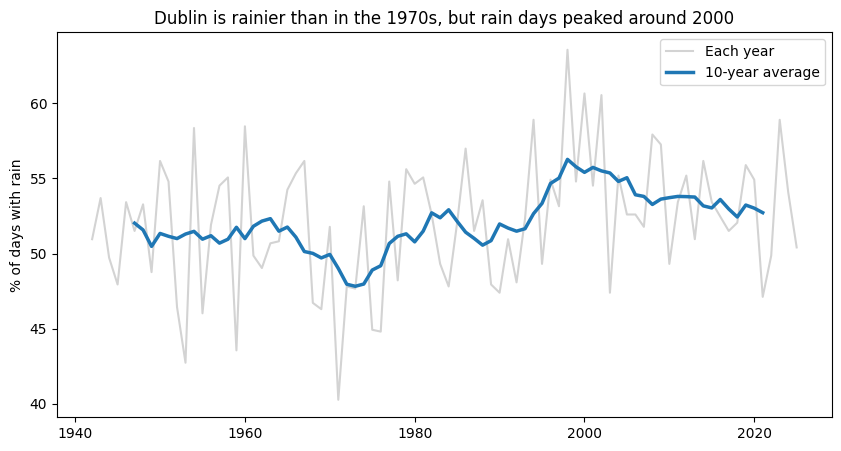

Change per decade: +0.44 percentage points
p-value: 0.022


In [87]:
from scipy import stats

yearly_pct = df.groupby("year")["rain_day"].mean() * 100
yearly_pct = yearly_pct.loc[:2025]          # complete years only, like before

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly_pct.index, yearly_pct, color="lightgrey", label="Each year")
ax.plot(yearly_pct.index, yearly_pct.rolling(10, center=True).mean(),
        linewidth=2.5, label="10-year average")
ax.set_ylabel("% of days with rain")
ax.set_title("Dublin is rainier than in the 1970s, but rain days peaked around 2000")
ax.legend()
plt.savefig("../figures/02_rain_days_trend.png", dpi=200, bbox_inches="tight")
plt.show()

trend = stats.linregress(yearly_pct.index, yearly_pct)
print(f"Change per decade: {trend.slope * 10:+.2f} percentage points")
print(f"p-value: {trend.pvalue:.3f}")

The estimated trend is about 13–14 additional rain days per year compared with the 1940s (p = 0.022). However, rain days peaked around 2000 rather than rising steadily, so the trend line alone hides the shape of the record.


In [88]:
def longest_streak(mask):
    streak_id = (mask != mask.shift()).cumsum()        # new ID every time the value flips
    lengths = mask.groupby(streak_id).agg(["first", "size"])
    lengths = lengths[lengths["first"]]               # keep only the streaks where mask is True
    best_id = lengths["size"].idxmax()
    start = df.loc[streak_id == best_id, "date"].iloc[0]
    return lengths["size"].max(), start

wet_len, wet_start = longest_streak(df["rain_day"])
dry_len, dry_start = longest_streak(~df["rain_day"])     # ~ means "not"

print(f"Longest rainy streak: {wet_len} days, starting {wet_start:%d %b %Y}")
print(f"Longest dry streak:   {dry_len} days, starting {dry_start:%d %b %Y}")

Longest rainy streak: 30 days, starting 01 May 1967
Longest dry streak:   31 days, starting 07 Aug 1947


The longest rainy streak was 30 days, starting 1 May 1967; the longest dry streak was 31 days, starting 7 August 1947.


In [89]:
tomorrow = df["rain_day"].shift(-1)       # tomorrow's value, lined up with today

print(f"Chance of rain tomorrow if it rained today: {tomorrow[df['rain_day']].mean():.1%}")
print(f"Chance of rain tomorrow if today was dry:   {tomorrow[~df['rain_day']].mean():.1%}")

Chance of rain tomorrow if it rained today: 66.4%
Chance of rain tomorrow if today was dry:   36.5%


Rain on one day was followed by rain the next day 66.4% of the time; after a dry day, the chance was 36.5%.


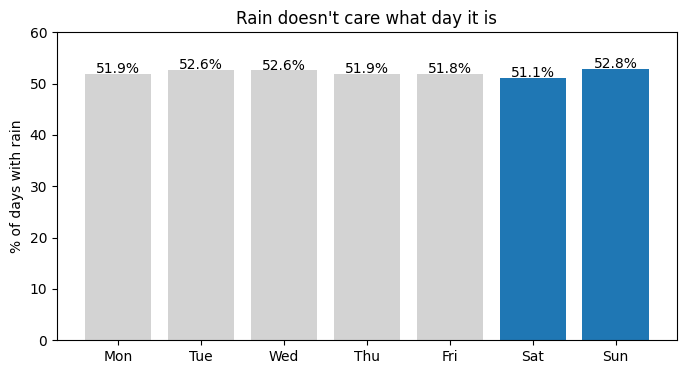

rain_day  False  True 
weekend               
False     10578  11532
True       4250   4594
Weekday: 52.2%
Weekend: 51.9%
p-value: 0.745


In [90]:
df["weekday"] = df["date"].dt.dayofweek        # 0 = Monday ... 6 = Sunday
by_day = df.groupby("weekday")["rain_day"].mean() * 100

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
colors = ["lightgrey"] * 5 + ["tab:blue"] * 2   # highlight the weekend

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(days, by_day, color=colors)
ax.set_ylim(0, 60)
ax.set_title("Rain doesn't care what day it is")   
ax.set_ylabel("% of days with rain")

for i, v in enumerate(by_day):
    ax.text(i, v + 0.2, f"{v:.1f}%", ha="center")
plt.savefig("../figures/03_weekend_myth.png", dpi=200, bbox_inches="tight")
plt.show()

# Chi-square test: weekend vs weekday
df["weekend"] = df["weekday"] >= 5
table = pd.crosstab(df["weekend"], df["rain_day"])
chi2, p, _, _ = stats.chi2_contingency(table)
print(table)
print(f"Weekday: {df.loc[~df['weekend'], 'rain_day'].mean():.1%}")
print(f"Weekend: {df.loc[df['weekend'], 'rain_day'].mean():.1%}")
print(f"p-value: {p:.3f}")

Rain-day rates were nearly identical on weekdays (52.2%) and weekends (51.9%; p = 0.75). There is no evidence here that rain favors weekends.


## 3. Predicting rain tomorrow


In [91]:
import numpy as np


df["rain_3d"] = df["rain"].rolling(3).sum()                                # total rain over the last 3 days
df["pressure_change"] = df["cbl"].diff()       # today's pressure minus yesterday's
df["target"] = (df["rain"].shift(-1) >= 1.0).astype(float)
df.loc[df["rain"].shift(-1).isna(), "target"] = np.nan
f = df[df["year"] >= 1950].copy()
f["temp_range"] = f["maxtp"] - f["mintp"]           # cloudy days have a small range
f["month_sin"] = np.sin(2 * np.pi * f["month"] / 12)
f["month_cos"] = np.cos(2 * np.pi * f["month"] / 12)

f[["date", "rain", "rain_3d", "cbl", "pressure_change", "temp_range"]].head()

,date,rain,rain_3d,cbl,pressure_change,temp_range
2922,1950-01-01,0.3,0.5,1016.8,6.7,6.7
2923,1950-01-02,1.1,1.4,1012.8,-4.0,1.9
2924,1950-01-03,0.2,1.6,1009.6,-3.2,2.4
2925,1950-01-04,0.0,1.3,1003.7,-5.9,1.1
2926,1950-01-05,0.4,0.6,991.8,-11.9,10.5


In [92]:
FEATURES = ["rain", "rain_3d", "cbl", "pressure_change", "temp_range",
            "maxtp", "mintp", "wdsp", "hg", "sun", "month_sin", "month_cos"]

f = f.dropna(subset=FEATURES + ["target"])

In [93]:
train = f[(f["year"] >= 1950) & (f["year"] <= 2009)]
val = f[(f["year"] >= 2010) & (f["year"] <= 2016)]
test = f[f["year"] >= 2017]

for name, data in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name}: {len(data)} rows, {data['target'].mean() * 100:.1f}% wet tomorrow")

Train: 21911 rows, 35.9% wet tomorrow
Validation: 2557 rows, 38.1% wet tomorrow
Test: 3559 rows, 36.4% wet tomorrow


The split is chronological—train on 1950–2009, tune on 2010–2016, and test from 2017 onward—so future data stays held out instead of randomly mixing neighboring days.


In [94]:
f[["date", "rain", "target"]].tail(3)

,date,rain,target
30950,2026-09-27,31.0,0.0
30951,2026-09-28,0.0,1.0
30952,2026-09-29,6.4,1.0


In [95]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

y_test = test["target"]

pred_dry = np.zeros(len(test))
pred_persist = (test["rain"] >= 1.0).astype(int)
monthly_rate = train.groupby("month")["target"].mean()
pred_month = (test["month"].map(monthly_rate) > 0.5).astype(int)

for name, pred in [("Always dry", pred_dry), ("Persistence", pred_persist), ("Monthly average", pred_month)]:
    print(f"{name:16} accuracy {accuracy_score(y_test, pred):.1%}   balanced {balanced_accuracy_score(y_test, pred):.1%}")

Always dry       accuracy 63.6%   balanced 50.0%
Persistence      accuracy 64.7%   balanced 61.9%
Monthly average  accuracy 63.6%   balanced 50.0%


The always-dry baseline gets 63.6% accuracy but only 50.0% balanced accuracy. Persistence (predicting tomorrow from today) reaches 61.9% balanced accuracy, the benchmark for the models.


In [96]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_train, y_train = train[FEATURES], train["target"]
X_val,   y_val   = val[FEATURES],   val["target"]
X_test,  y_test  = test[FEATURES],  test["target"]

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)                  # train the model

prob_lr = logreg.predict_proba(X_test)[:, 1]  # chance of "wet tomorrow" for each test day
pred_lr = (prob_lr >= 0.5).astype(int)        # turn probability into yes/no

print(f"Logistic regression  accuracy {accuracy_score(y_test, pred_lr):.1%}   balanced {balanced_accuracy_score(y_test, pred_lr):.1%}")

Logistic regression  accuracy 66.6%   balanced 59.2%


At the default 0.5 cutoff, logistic regression reaches 59.2% balanced accuracy—below the 61.9% persistence baseline.


In [97]:
thresholds = np.arange(0.20, 0.71, 0.01)
prob_val = logreg.predict_proba(X_val)[:, 1]

scores = [balanced_accuracy_score(y_val, prob_val >= t) for t in thresholds]
best_t = thresholds[np.argmax(scores)]
print(f"Best threshold on validation: {best_t:.2f}")

pred_lr = (prob_lr >= best_t).astype(int)        # apply it to the TEST set
print(f"Logistic regression (tuned)  accuracy {accuracy_score(y_test, pred_lr):.1%}   balanced {balanced_accuracy_score(y_test, pred_lr):.1%}")

Best threshold on validation: 0.32
Logistic regression (tuned)  accuracy 65.4%   balanced 67.2%


Tuning the decision threshold on validation data raises logistic regression to 67.2% balanced accuracy on the held-out test set, above persistence.


In [98]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=20, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

prob_rf = rf.predict_proba(X_test)[:, 1]

In [99]:
prob_val_rf = rf.predict_proba(X_val)[:, 1]
scores_rf = [balanced_accuracy_score(y_val, prob_val_rf >= t) for t in thresholds]
best_t_rf = thresholds[np.argmax(scores_rf)]
print(f"Best random-forest threshold on validation: {best_t_rf:.2f}")

pred_rf = (prob_rf >= best_t_rf).astype(int)
print(f"Random forest (tuned)  accuracy {accuracy_score(y_test, pred_rf):.1%}   balanced {balanced_accuracy_score(y_test, pred_rf):.1%}")

Best random-forest threshold on validation: 0.39
Random forest (tuned)  accuracy 66.4%   balanced 67.6%


The tuned random forest reaches 67.6% balanced accuracy, a small improvement over tuned logistic regression (67.2%) and persistence (61.9%).


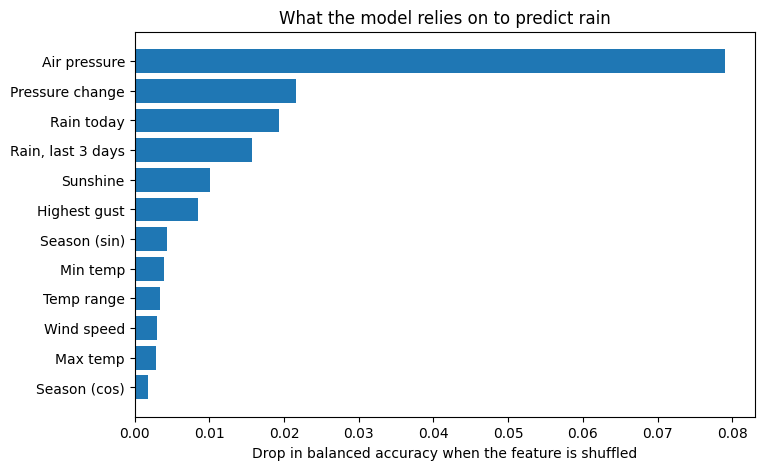

In [100]:
from sklearn.inspection import permutation_importance

result = permutation_importance(rf, X_test, y_test, scoring="balanced_accuracy",
                                n_repeats=10, random_state=42, n_jobs=-1)
importance = pd.Series(result.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importance = importance.rename({"cbl": "Air pressure", "pressure_change": "Pressure change",
      "rain": "Rain today", "rain_3d": "Rain, last 3 days", "wdsp": "Wind speed",
      "sun": "Sunshine", "hg": "Highest gust", "maxtp": "Max temp", "mintp": "Min temp",
      "temp_range": "Temp range", "month_sin": "Season (sin)", "month_cos": "Season (cos)"})
ax.barh(importance.index, importance.values)
ax.set_xlabel("Drop in balanced accuracy when the feature is shuffled")
ax.set_title("What the model relies on to predict rain")
plt.savefig("../figures/04_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

Air pressure stands out as the strongest feature, followed by pressure change, rain today, and recent rainfall. Permutation importance shows model reliance, not proof that a feature causes rain.
